# 珍珠(Masyu)：用有向边与无向边表示圆上的条件

## 这一章讲什么

珍珠这个谜题，要求一条回路穿过盘面上所有的白圆与黑圆。回路本身的形状交给 `add_circuit()` 即可，真正需要自己动手的是另一件事，即走到圆上的时候究竟应当拐弯还是应当直走，这正是本章的重点。

- 有向边管回路，无向边管条件，两套边要对得上
- 用“横线数减竖线数”判断是不是拐弯
- 白圆要直行，黑圆要直角，而且黑圆前后那两格不能再拐

## 规则

1. 在盘面上画线，整体围成一条闭合的回路。
2. 线从方格正中穿过，不交叉，也不分叉。
3. 所有的白圆和黑圆都要被线经过。
4. 线经过白圆时，在白圆这一格里必须直行，并且在相邻的格子拐直角(只在一侧拐也算)。
5. 线经过黑圆时，在黑圆这一格里必须拐直角，相邻的格子则不能拐，与白圆的条件正好相反。

![](https://www.nikoli.co.jp/ja/wp-content/themes/nikoli/images/puzzles/masyu03.gif)

`````{admonition} 珍珠谜题的网站
:class: tip
https://ja.puzzle-masyu.com/

用 `helper.puzzle.extract_masyu()` 能够把这个网站的谜题盘面取下来。打开浏览器的开发者工具，复制表示盘面的 `<div>` 标签代码，再运行这个函数，盘面就变成数组了。
`````

## 盘面

`1` 是白圆，`2` 是黑圆，`0` 表示这里什么都没有，盘面以二维数组的形式给出。

In [1]:
from ortools.sat.python import cp_model
import numpy as np

puzzle = np.loadtxt('data/masyu01.txt', dtype=np.uint8)
print(puzzle)

[[0 1 0 0 1 0 0 2]
 [0 0 0 0 0 1 0 0]
 [0 0 2 0 0 1 0 0]
 [0 0 1 0 1 1 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 2 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 2]]


## 思路

既然要的是一条经过所有圆的回路，`add_circuit()` 直接就能用上。麻烦在于有些方格不用走，那就给没有圆的方格各加一条自环 `(i, i)`，让它们各自闭合。

`add_circuit()` 认的边是有向的。相邻两个方格 `a`、`b` 之间摆两条，即 `a → b` 与 `b → a`，回路通过时只会取其中一条。

由于圆的条件(该拐还是该直)写起来不分方向，因此一条有向边不足以表达它，需要另想办法。我们让两条有向边 `e1`、`e2` 合出一条无向边 `e`，圆的条件就统一写在这条边上。

```python
model.add(e == e1 + e2)   # 只要其中一条为真，无向边就“有线段”
```

有了它，圆所在方格四周的线就能当成上、下、左、右 4 条无向线来数，其值只可能是 0 或 1。

位置的叫法也得定一下，注意紧贴圆那一格的四条线记作 $U_1, D_1, L_1, R_1$，再往外一格的记作 $U_2, D_2, L_2, R_2$。

![](images/masyu.svg)

为了判断是否拐弯，需要使用下面的式子。

$$
L_1 + R_1 - U_1 - D_1
$$

- 直行(左右)：$1+1-0-0 = 2$
- 直行(上下)：$0+0-1-1 = -2$
- 直角(左加上)：$1+0-1-0 = 0$

因此 0 代表拐弯，不是 0 就代表直行，两者正好相反。

| 圆 | 条件 |
|---|---|
| 白圆 | $L_1 + R_1 - U_1 - D_1 \neq 0$(直行) |
| 黑圆 | $L_1 + R_1 - U_1 - D_1 = 0$(直角) |

黑圆还得多说一句：$L_1 \rightarrow L_2$ 这样的蕴含要写出来，保证相邻那格不再拐，也就是从黑圆出去的那条线，下一格必须直行。

In [2]:
def solve_masyu(puzzle):
    """求解珍珠谜题，返回用到的有向边列表"""
    h, w = puzzle.shape
    nodes = np.arange(h * w).reshape(h, w)

    # 有向边（用于回路）和无向边（用于圆的条件）
    directed_edges = []
    edges = []
    for (r, c), n1 in np.ndenumerate(nodes):
        if c + 1 < w:
            n2 = nodes[r, c + 1]
            directed_edges.extend([(n1, n2), (n2, n1)])
            edges.append((n1, n2))
        if r + 1 < h:
            n2 = nodes[r + 1, c]
            directed_edges.extend([(n1, n2), (n2, n1)])
            edges.append((n1, n2))

    model = cp_model.CpModel()
    directed_edge_variables = {e: model.new_bool_var(f'dedge_{e}') for e in directed_edges}
    edge_variables = {e: model.new_bool_var(f'edge_{e}') for e in edges}

    # 没有圆的方格可以脱离回路（自环）
    dummy_variables = {(i, i): model.new_bool_var(f'dummy_{i}')
                       for (r, c), i in np.ndenumerate(nodes) if puzzle[r, c] == 0}

    model.add_circuit(
        [(n1, n2, v) for (n1, n2), v in directed_edge_variables.items()] +
        [(n1, n2, v) for (n1, n2), v in dummy_variables.items()])

    # 无向边 = 两条有向边中的一条
    for (n1, n2), b in edge_variables.items():
        model.add(b == directed_edge_variables[n1, n2] + directed_edge_variables[n2, n1])

    directs = dict(u=(-1, 0), d=(1, 0), l=(0, -1), r=(0, 1))

    for (r, c), num in np.ndenumerate(puzzle):
        node = nodes[r, c]
        step1 = {}
        step2 = {}
        for name, (dr, dc) in directs.items():
            r1, c1 = r + dr, c + dc
            r2, c2 = r + dr * 2, c + dc * 2
            if 0 <= r1 < h and 0 <= c1 < w:
                n1, n2 = sorted([node, nodes[r1, c1]])
                step1[name] = edge_variables[n1, n2]
                if 0 <= r2 < h and 0 <= c2 < w:
                    n1, n2 = sorted([nodes[r1, c1], nodes[r2, c2]])
                    step2[name] = edge_variables[n1, n2]

        # 通向盘外的方向当作 0（没有线）
        l, r_, u, d = [step1.get(direction, 0) for direction in 'lrud']
        expr = l + r_ - u - d

        if num == 1:      # 白圆：直行
            model.add(expr != 0)
        elif num == 2:    # 黑圆：直角
            model.add(expr == 0)
            for direction in "lrud":
                if direction in step2:
                    # 从黑圆出来的线，在下一格不转弯
                    model.add_implication(step1[direction], step2[direction])
                elif direction in step1:
                    # 两格之外在盘外，就不能往这个方向走
                    model.add_bool_and(~step1[direction])

    solver = cp_model.CpSolver()
    if solver.solve(model) not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        raise ValueError("没有找到解")

    return [key for key, v in directed_edge_variables.items() if solver.value(v)]

## 画图

把盘面和回路都画出来看看，确认回路的形状。

In [3]:
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection


def plot_masyu_board(puzzle, route):
    """画出盘面和回路"""
    h, w = puzzle.shape
    fig, ax = plt.subplots(figsize=(w * 0.3, h * 0.3))

    segments = []
    for n1, n2 in route:
        r1, c1 = n1 // w, n1 % w
        r2, c2 = n2 // w, n2 % w
        segments.append([(c1, r1), (c2, r2)])
    ax.add_collection(LineCollection(segments, color='black'))

    r, c = np.where(puzzle == 1)
    ax.scatter(c, r, s=100, marker='o', facecolor="none", edgecolor="black")
    r, c = np.where(puzzle == 2)
    ax.scatter(c, r, s=100, marker='o', facecolor="black", edgecolor="black")

    ax.set_aspect('equal')
    ax.invert_yaxis()
    ax.axis('off')
    return fig, ax

## 简单的盘面

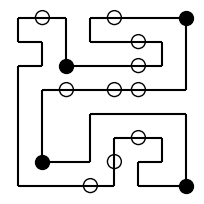

In [4]:
puzzle = np.loadtxt('data/masyu01.txt', dtype=np.uint8)
route = solve_masyu(puzzle)
plot_masyu_board(puzzle, route);

## 最难的盘面

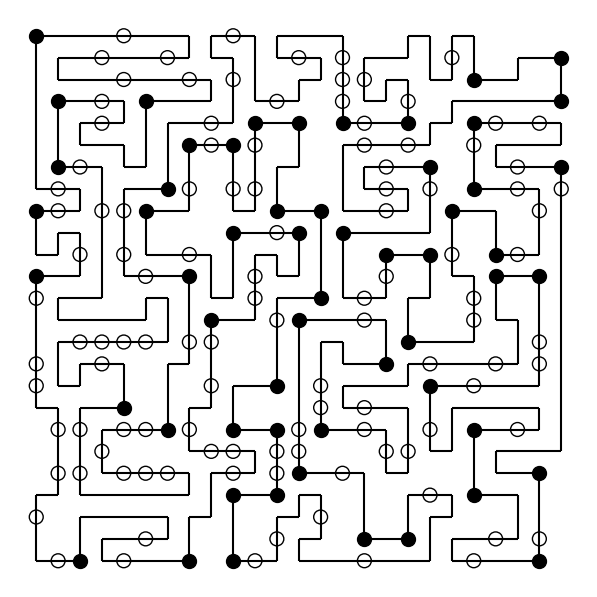

In [5]:
puzzle = np.loadtxt('data/masyu02.txt', dtype=np.uint8)
route = solve_masyu(puzzle)
plot_masyu_board(puzzle, route);

## 验算

解出来的回路过不过得了圆的条件，得核一遍，因此后面还要写一段验算代码。

In [6]:
def check_masyu(puzzle, route):
    """确认圆所在的格是否直行或直角，以及回路是否只有一条"""
    h, w = puzzle.shape
    adj = {}
    for n1, n2 in route:
        adj.setdefault(n1, []).append(n2)
        adj.setdefault(n2, []).append(n1)

    def step(n1, n2):
        r1, c1 = divmod(n1, w)
        r2, c2 = divmod(n2, w)
        return r2 - r1, c2 - c1

    # 1. 是否经过圆所在的格，并满足条件
    for (r, c), v in np.ndenumerate(puzzle):
        if v == 0:
            continue
        node = r * w + c
        if node not in adj or len(adj[node]) != 2:
            return False, f"圆 {(r, c)} 没有被经过"
        d1, d2 = (step(node, adj[node][0]), step(node, adj[node][1]))
        horizontal = d1[0] == 0 and d2[0] == 0
        vertical = d1[1] == 0 and d2[1] == 0
        if v == 1 and not (horizontal or vertical):
            return False, f"白圆 {(r, c)} 处不是直行"
        if v == 2 and (horizontal or vertical):
            return False, f"黑圆 {(r, c)} 处不是直角"

    # 2. 回路是否只有一条
    start = next(iter(adj))
    prev, cur, count = None, start, 0
    while True:
        count += 1
        nxt = adj[cur][0] if adj[cur][0] != prev else adj[cur][1]
        prev, cur = cur, nxt
        if cur == start:
            break
    if count != len(adj):
        return False, "回路不是一条"
    return True, f"{count} 个方格组成的一条回路"


print(check_masyu(puzzle, route))

(True, '544 个方格组成的一条回路')


## 小结

- 回路交给 `add_circuit()`，不走的地方用自环 `(i, i)` 顶上
- `e == e1 + e2` 一写，两条有向边就并成无向边，圆的条件跟着好写
- 究竟拐没拐弯，看 `L + R - U - D` 等不等于 0，例如直行取 ±2，直角取 0
- 黑圆另加 `add_implication()`，把“相邻格不拐”明写出来
- 朝向盘外的方向当作 `0`，也就是没有线，其值照样混进式子里计算